# **Fire Risk ANN**

Steps:
1) Load packages and data
2) Data preprocessing
3) Create, train, and evaluate model

**Step 1: Load packages and data**

In [ ]:
# 1
import numpy as np
import pandas as pd

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving TEST 11_26 Temp + Hum Fire Data Western US - Sheet1.csv to TEST 11_26 Temp + Hum Fire Data Western US - Sheet1.csv


In [ ]:
# 2
# Load in csv files as dataframes
train = pd.read_csv('/content/TRAIN 11_26 Temp + Hum Fire Data Western US - Sheet1.csv')
test = pd.read_csv('/content/TEST 11_26 Temp + Hum Fire Data Western US - Sheet1.csv')

df = pd.concat([train, test], axis = 0, sort = True)
df.head()
df.tail()

,Max Hum,Min Hum,Prob,Temp
7,71,33,NaN,42
8,54,26,NaN,44
9,35,20,NaN,48
10,33,21,NaN,48
11,33,22,NaN,50


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# 3
df.describe()

,Max Hum,Min Hum,Prob,Temp
count,54.000000,54.000000,42.000000,54.000000
mean,45.944444,27.981481,0.467857,58.111111
std,19.104891,16.225406,0.300378,15.447619
min,21.000000,12.000000,0.000000,26.000000
25%,33.000000,18.250000,0.170000,45.000000
50%,40.000000,23.000000,0.500000,63.000000
75%,54.000000,29.500000,0.670000,72.000000
max,91.000000,91.000000,1.000000,79.000000


**Step 2: Data preprocessing**

1) Encoding categorical values
2) Scaling continuous values

In [ ]:
# 4
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.pyplot import rcParams
%matplotlib inline
rcParams['figure.figsize'] = 10,8
sns.set(style='whitegrid', palette='muted',
        rc={'figure.figsize': (15,10)})

<Axes: xlabel='Title', ylabel='count'>

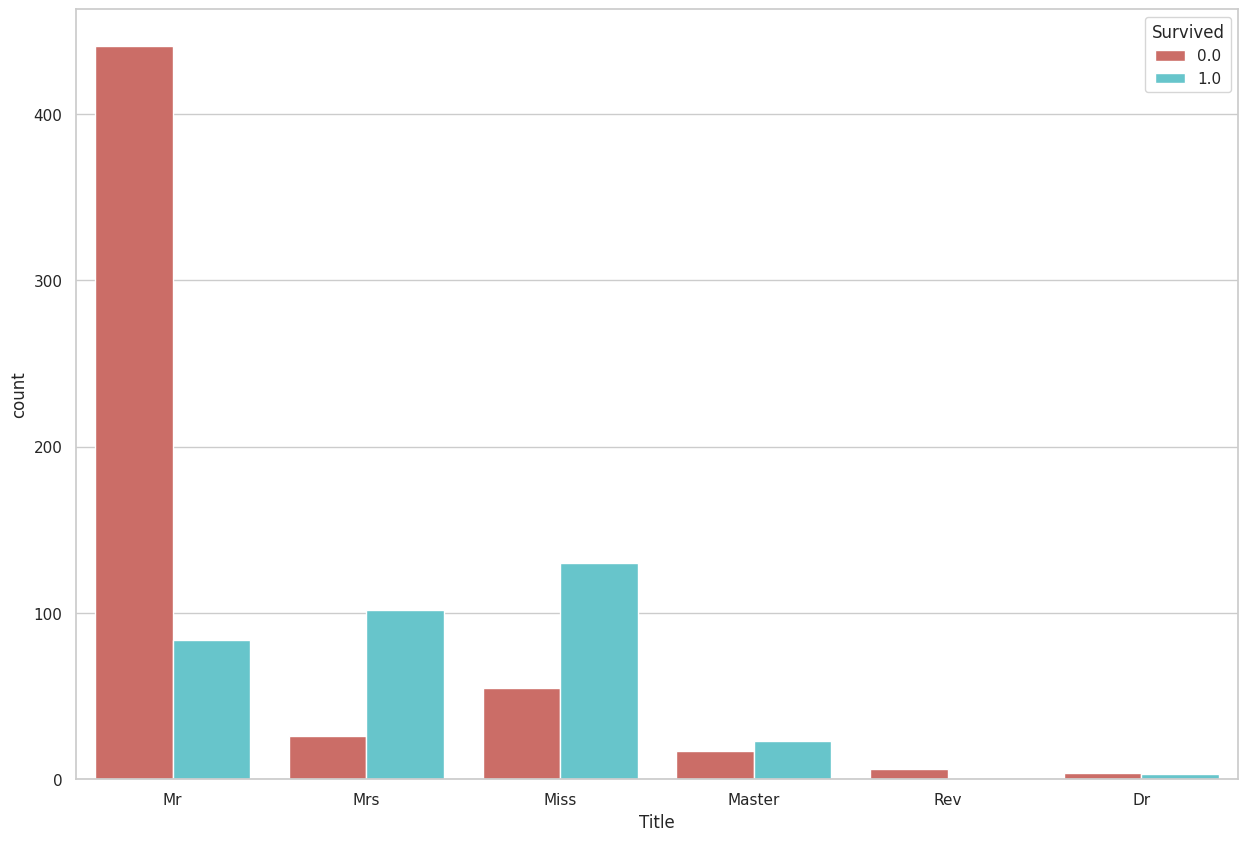

In [ ]:
# 5
sns.countplot(x = 'Title', data = df, palette = 'hls', hue = 'Survived')

<Axes: xlabel='Sex', ylabel='count'>

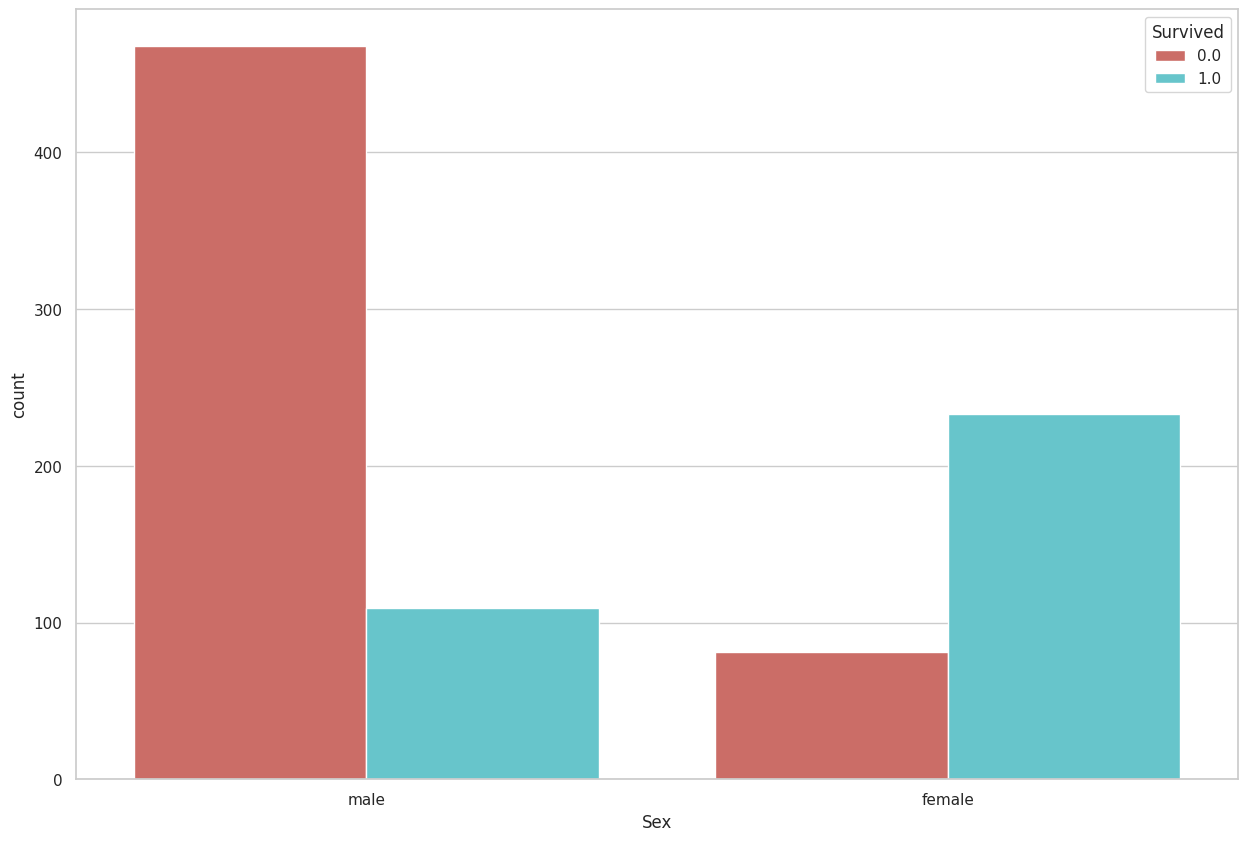

In [ ]:
# 6
sns.countplot(x = 'Sex', data = df, palette = 'hls', hue = 'Survived')

<Axes: xlabel='Embarked', ylabel='count'>

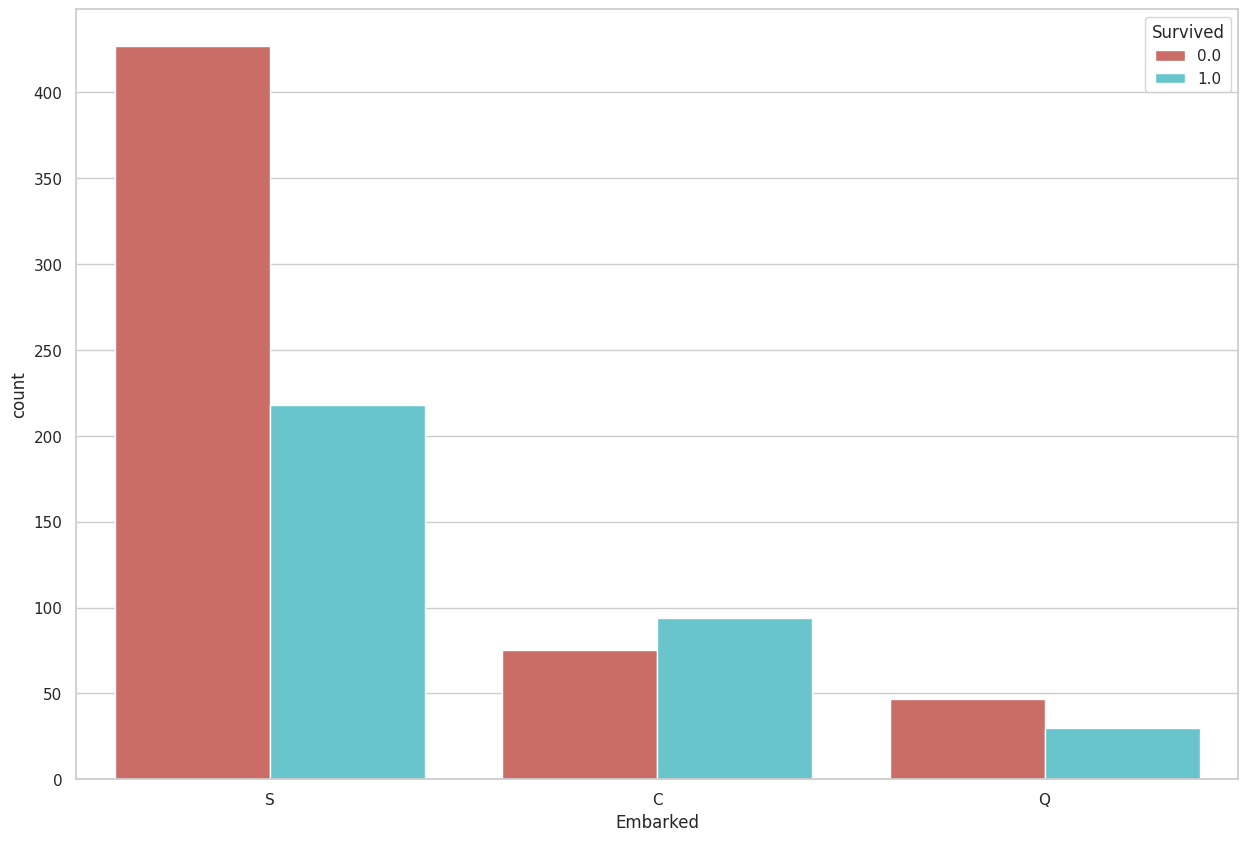

In [ ]:
# 7
sns.countplot(x = 'Embarked', data = df, palette = 'hls', hue = 'Survived')

In [ ]:
# 8
df.head()

,Max Hum,Min Hum,Prob,Temp
0,37,24,0.83,79
1,51,23,0.83,77
2,33,22,0.67,72
3,33,18,0.67,72
4,25,14,1.00,76


In [ ]:
df.dtypes

,0
Max Hum,int64
Min Hum,int64
Prob,float64
Temp,int64


In [ ]:
# 9
# convert sex to binary 1/0 values:
df['Sex'] = df['Sex'].astype('category').cat.codes
df.head()

,Age,Cabin,Embarked,Family_Size,Fare,Name,Parch,PassengerId,Pclass,Sex,SibSp,Survived,Ticket,Title
0,22.0,NaN,S,1,7.2500,"Braund, Mr. Owen Harris",0,1,3,1,1,0.0,A/5 21171,Mr
1,38.0,C85,C,1,71.2833,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,2,1,0,1,1.0,PC 17599,Mrs
2,26.0,NaN,S,0,7.9250,"Heikkinen, Miss. Laina",0,3,3,0,0,1.0,STON/O2. 3101282,Miss
3,35.0,C123,S,1,53.1000,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,4,1,0,1,1.0,113803,Mrs
4,35.0,NaN,S,0,8.0500,"Allen, Mr. William Henry",0,5,3,1,0,0.0,373450,Mr


In [ ]:
df.dtypes

Age            float64
Cabin           object
Embarked        object
Family_Size      int64
Fare           float64
Name            object
Parch            int64
PassengerId      int64
Pclass           int64
Sex               int8
SibSp            int64
Survived       float64
Ticket          object
Title           object
dtype: object

In [ ]:
# 10
# convert sex to binary 1/0 values:
df['Embarked'] = df['Embarked'].astype('category').cat.codes
df['Title'] = df['Title'].astype('category').cat.codes
df.head()

,Age,Cabin,Embarked,Family_Size,Fare,Name,Parch,PassengerId,Pclass,Sex,SibSp,Survived,Ticket,Title
0,22.0,NaN,2,1,7.2500,"Braund, Mr. Owen Harris",0,1,3,1,1,0.0,A/5 21171,3
1,38.0,C85,0,1,71.2833,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,2,1,0,1,1.0,PC 17599,4
2,26.0,NaN,2,0,7.9250,"Heikkinen, Miss. Laina",0,3,3,0,0,1.0,STON/O2. 3101282,2
3,35.0,C123,2,1,53.1000,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,4,1,0,1,1.0,113803,4
4,35.0,NaN,2,0,8.0500,"Allen, Mr. William Henry",0,5,3,1,0,0.0,373450,3


In [ ]:
# 11
# Drop some identification features
df.drop(['Cabin', 'Name', 'Ticket', 'PassengerId'], axis = 1,  inplace = True)
df.head()

,Age,Embarked,Family_Size,Fare,Parch,Pclass,Sex,SibSp,Survived,Title
0,22.0,2,1,7.2500,0,3,1,1,0.0,3
1,38.0,0,1,71.2833,0,1,0,1,1.0,4
2,26.0,2,0,7.9250,0,3,0,0,1.0,2
3,35.0,2,1,53.1000,0,1,0,1,1.0,4
4,35.0,2,0,8.0500,0,3,1,0,0.0,3


**regulation**

In [ ]:
# 12
import os
from sklearn.preprocessing import StandardScaler
features = ['Min Hum', 'Temp', 'Max Hum']
scaler = StandardScaler()
for var in features:
  df[var] = df[var].astype('float64')
  df[var] = scaler.fit_transform(df[var].values.reshape(-1,1))  # mean = 0, and stddev = 1

df.head()

,Max Hum,Min Hum,Prob,Temp
0,-0.472572,-0.247690,0.83,1.364937
1,0.267106,-0.309900,0.83,1.234252
2,-0.683908,-0.372111,0.67,0.907538
3,-0.683908,-0.620952,0.67,0.907538
4,-1.106581,-0.869794,1.00,1.168909


**Step 3: Create, train, and evaluate the neural network!**

In [ ]:
# 13
# Separate data back into train and test
x_train = df[pd.notnull(df['Prob'])].drop(['Prob'],axis=1)
x_train.head()


,Max Hum,Min Hum,Temp
0,-0.472572,-0.247690,1.364937
1,0.267106,-0.309900,1.234252
2,-0.683908,-0.372111,0.907538
3,-0.683908,-0.620952,0.907538
4,-1.106581,-0.869794,1.168909


In [ ]:
# 14
# Separate data back into train and test
y_train = df[pd.notnull(df['Prob'])]['Prob']
y_train.head()
y_train.tail()


,Prob
37,0.50
38,0.66
39,0.66
40,0.66
41,0.66


In [ ]:
# 15
# Separate data back into train and test
x_test = df[pd.isnull(df['Prob'])].drop(['Prob'],axis=1)
x_test.head()

,Max Hum,Min Hum,Temp
0,1.904963,2.551781,-0.399317
1,1.746461,0.125573,-0.922059
2,-0.102733,-0.061058,-0.922059
3,-0.525406,-0.372111,-0.791373
4,-0.578240,-0.372111,-0.726031


**Define a NN model**


In [ ]:
# 16
from sklearn.model_selection import train_test_split
from keras.models import Sequential
from keras.layers import Dense, Activation, Dropout

from numpy.random import seed

In [ ]:
# 17
print(x_train.shape[1])

3


Dropout is a regularization method approximating concurrent training of many neural networks with various designs. During training, some layer outputs are ignored or dropped at random. This makes the layer appear and is regarded as having a different number of nodes and connectedness to the preceding layer.

In [ ]:
# 18
def create_model(act='relu', opt='Adam', dr=0.0):
# activation function = relu, gradient descent optimization = Adam

    model = Sequential() # Multilayer Feedforward Backprogation NN

    # create first hidden layer
    model.add(Dense(8, input_dim= x_train.shape[1], activation=act))

    # add dropout
    model.add(Dropout(dr))

    # create output layer
    model.add(Dense(1, activation='sigmoid'))

    model.compile(loss='binary_crossentropy', optimizer=opt, metrics=['accuracy'])

    return model





In [ ]:
# 19
model = create_model(dr=0.2)
print(model.summary())

/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                      │ (None, 8)                   │              32 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 8)                   │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │               9 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 41 (164.00 B)

 Trainable params: 41 (164.00 B)

 Non-trainable params: 0 (0.00 B)

None


In [ ]:
# 20
# train model with 80/20 CV split

training = model.fit(x_train, y_train, epochs=75, batch_size=32, validation_split=0.2, verbose=0)
# validation_split = Fraction of the training data to be used as validation data

scores = model.evaluate(x_train, y_train)
print("validation accuracy:", scores[1]*100)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.1736 - loss: 0.5860 
validation accuracy: 16.66666716337204


In [ ]:
# 21
# model predict on test data
test['Prob'] = model.predict(x_test)



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step


In [ ]:
# 22
# Test the prediction result
s1 = model.predict(x_test)
print(s1[:20])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
[[0.04835881]
 [0.26018316]
 [0.44615066]
 [0.46562856]
 [0.46275696]
 [0.46585688]
 [0.03614872]
 [0.25091207]
 [0.39924842]
 [0.4739482 ]
 [0.46028024]
 [0.458568  ]]


In [ ]:
# 23
# model predict on test data
test['Prob'] = model.predict(x_test)
test.head(20)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


,Min Hum,Temp,Max Hum,Prob
0,69,52,82,0.048359
1,30,44,79,0.260183
2,27,44,44,0.446151
3,22,46,36,0.465629
4,22,47,35,0.462757
5,22,49,35,0.465857
6,74,49,85,0.036149
7,33,42,71,0.250912
8,26,44,54,0.399248
9,20,48,35,0.473948


In [ ]:
# 24
# round outputs to 1 or 0
test['Prob'] = test['Prob'].apply(lambda x: round(x,0)).astype('int')
solution = test[['Max Hum', 'Prob']]

In [ ]:
solution.head(20)

,Max Hum,Prob
0,82,0
1,79,0
2,44,0
3,36,0
4,35,0
5,35,0
6,85,0
7,71,0
8,54,0
9,35,0
